# Серия экспериментов: single label flip на нескольких seed

Ноутбук запускает и сопоставляет чистый контроль и умеренную атаку `1 → 7` для seed **42, 43, 44**. Он формирует таблицы среднего и разброса, графики с доверительным разбросом и CSV-артефакты для первоначального отчёта.

## 1. Конфигурация серии

In [22]:
import json
import os
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from IPython.display import Markdown, display
except ImportError:
    Markdown = str
    def display(value):
        return value

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'pyproject.toml').exists():
    PROJECT_ROOT = next(path for path in [PROJECT_ROOT, *PROJECT_ROOT.parents] if (path / 'pyproject.toml').exists())
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from fl_benchmark.config import load_config
from fl_benchmark.task import run_local_simulation

SEEDS = (42, 43, 44)
NOTEBOOK_RESULTS_DIR = PROJECT_ROOT / 'notebooks' / 'results'
SERIES_ARTIFACT_DIR = NOTEBOOK_RESULTS_DIR / 'single-label-flip-seed-series'
SERIES_ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_PICS_DIR = PROJECT_ROOT / 'practice_report' / 'pics'
REPORT_PICS_DIR.mkdir(parents=True, exist_ok=True)
base_config = load_config(PROJECT_ROOT / 'configs' / 'mnist_label_flip.toml')

def config_for_seed(seed, attack_enabled):
    scenario = 'attack' if attack_enabled else 'clean-control'
    name = f'mnist-label-flip-{scenario}-seed-{seed}'
    attack = base_config.attack if attack_enabled else replace(base_config.attack, enabled=False, type='none', malicious_fraction=0.0, poison_fraction=0.0)
    return replace(
        base_config,
        name=name,
        partition=replace(base_config.partition, seed=seed),
        training=replace(base_config.training, seed=seed),
        attack=replace(attack, seed=seed),
        tracking=replace(base_config.tracking, output_dir=NOTEBOOK_RESULTS_DIR, experiment_name=name),
        source_path=None,
    )

display(pd.DataFrame([
    ('Seed', ', '.join(map(str, SEEDS))),
    ('Датасет / модель / стратегия', f'{base_config.dataset.name} / {base_config.model.name} / {base_config.strategy.name}'),
    ('Non-IID режим', f'{base_config.partition.type}, alpha={base_config.partition.alpha}'),
    ('Атака', f'{base_config.attack.source_label} → {base_config.attack.target_label}'),
    ('Вредоносные клиенты / доля отравления', f'{base_config.attack.malicious_fraction:.0%} / {base_config.attack.poison_fraction:.0%}'),
], columns=['Параметр', 'Значение']))

,Параметр,Значение
0,Seed,"42, 43, 44"
1,Датасет / модель / стратегия,mnist / mnist-cnn / fedavg
2,Non-IID режим,"dirichlet, alpha=0.5"
3,Атака,1 → 7
4,Вредоносные клиенты / доля отравления,20% / 50%


## 2. Выполнение парных запусков
Для каждого seed запускаются два эксперимента с совпадающими параметрами: чистый контроль и атака. Всего выполняется шесть полных запусков MNIST.

In [23]:
RUN_FULL_SERIES = True
run_paths = []

if RUN_FULL_SERIES:
    for seed in SEEDS:
        print(f'=== seed {seed}: контроль ===')
        clean_path = run_local_simulation(config_for_seed(seed, attack_enabled=False))
        print(f'=== seed {seed}: label flip ===')
        attack_path = run_local_simulation(config_for_seed(seed, attack_enabled=True))
        run_paths.append({'seed': seed, 'clean_path': clean_path, 'attack_path': attack_path})
else:
    def latest_result(prefix):
        matches = sorted(NOTEBOOK_RESULTS_DIR.glob(f'{prefix}-*'), key=lambda path: path.stat().st_mtime)
        if not matches:
            raise FileNotFoundError(f'Не найдены результаты {prefix!r}')
        return matches[-1]
    for seed in SEEDS:
        run_paths.append({'seed': seed, 'clean_path': latest_result(f'mnist-label-flip-clean-control-seed-{seed}'), 'attack_path': latest_result(f'mnist-label-flip-attack-seed-{seed}')})

display(pd.DataFrame(run_paths))

=== seed 42: контроль ===
=== seed 42: label flip ===
=== seed 43: контроль ===
=== seed 43: label flip ===
=== seed 44: контроль ===
=== seed 44: label flip ===


,seed,clean_path,attack_path
0,42,C:\Users\neko\Desktop\projects\fed-learning-st...,C:\Users\neko\Desktop\projects\fed-learning-st...
1,43,C:\Users\neko\Desktop\projects\fed-learning-st...,C:\Users\neko\Desktop\projects\fed-learning-st...
2,44,C:\Users\neko\Desktop\projects\fed-learning-st...,C:\Users\neko\Desktop\projects\fed-learning-st...


## 3. Агрегирование глобальных метрик
Среднее и стандартное отклонение рассчитываются по seed. Разность всегда задана как «атака − контроль» в пределах одного seed.

In [24]:
def load_run(path, seed, scenario):
    summary = json.loads((path / 'summary.json').read_text(encoding='utf-8'))
    per_class = pd.read_csv(path / 'final_per_class_metrics.csv')
    rounds = pd.read_csv(path / 'round_metrics.csv').assign(seed=seed, scenario=scenario)
    return summary, per_class.assign(seed=seed, scenario=scenario), rounds

global_rows, class_rows, round_frames = [], [], []
for record in run_paths:
    for scenario, path_key in [('control', 'clean_path'), ('attack', 'attack_path')]:
        summary, per_class, rounds = load_run(record[path_key], record['seed'], scenario)
        global_rows.append({'seed': record['seed'], 'scenario': scenario, 'accuracy': summary['final_accuracy'], 'loss': summary['final_loss'], 'macro_f1': summary['final_macro_f1'], 'duration_seconds': summary['total_duration_seconds'], 'poisoned_examples': summary['total_poisoned_examples']})
        class_rows.append(per_class)
        round_frames.append(rounds)
global_metrics = pd.DataFrame(global_rows)
class_metrics = pd.concat(class_rows, ignore_index=True)
round_metrics = pd.concat(round_frames, ignore_index=True)

paired = global_metrics.pivot(index='seed', columns='scenario', values=['accuracy', 'loss', 'macro_f1'])
deltas = pd.DataFrame({'seed': paired.index, 'accuracy_delta': paired[('accuracy', 'attack')] - paired[('accuracy', 'control')], 'loss_delta': paired[('loss', 'attack')] - paired[('loss', 'control')], 'macro_f1_delta': paired[('macro_f1', 'attack')] - paired[('macro_f1', 'control')]})
def flatten_summary_columns(frame):
    flattened = frame.copy()
    flattened.columns = [('_'.join(str(part) for part in column if part) if isinstance(column, tuple) else str(column)) for column in flattened.columns]
    return flattened

aggregate_global = global_metrics.groupby('scenario')[['accuracy', 'loss', 'macro_f1', 'duration_seconds', 'poisoned_examples']].agg(['mean', 'std'])
aggregate_global_export = flatten_summary_columns(aggregate_global.reset_index())
display(aggregate_global_export)
display(deltas)
global_metrics.to_csv(SERIES_ARTIFACT_DIR / 'global_metrics_per_seed.csv', index=False)
aggregate_global_export.to_csv(SERIES_ARTIFACT_DIR / 'global_metrics_summary.csv', index=False)
deltas.to_csv(SERIES_ARTIFACT_DIR / 'paired_deltas.csv', index=False)

,scenario,accuracy_mean,accuracy_std,loss_mean,loss_std,macro_f1_mean,macro_f1_std,duration_seconds_mean,duration_seconds_std,poisoned_examples_mean,poisoned_examples_std
0,attack,0.975133,0.001250,0.082686,0.007050,0.974969,0.001304,141.827903,0.583016,615.0,554.024368
1,control,0.974500,0.001353,0.081528,0.005287,0.974327,0.001435,145.969016,4.977278,0.0,0.000000


,seed,accuracy_delta,loss_delta,macro_f1_delta
seed,,,,
42,42,0.0008,0.001117,0.000863
43,43,0.0006,-0.000866,0.000601
44,44,0.0005,0.003224,0.000461


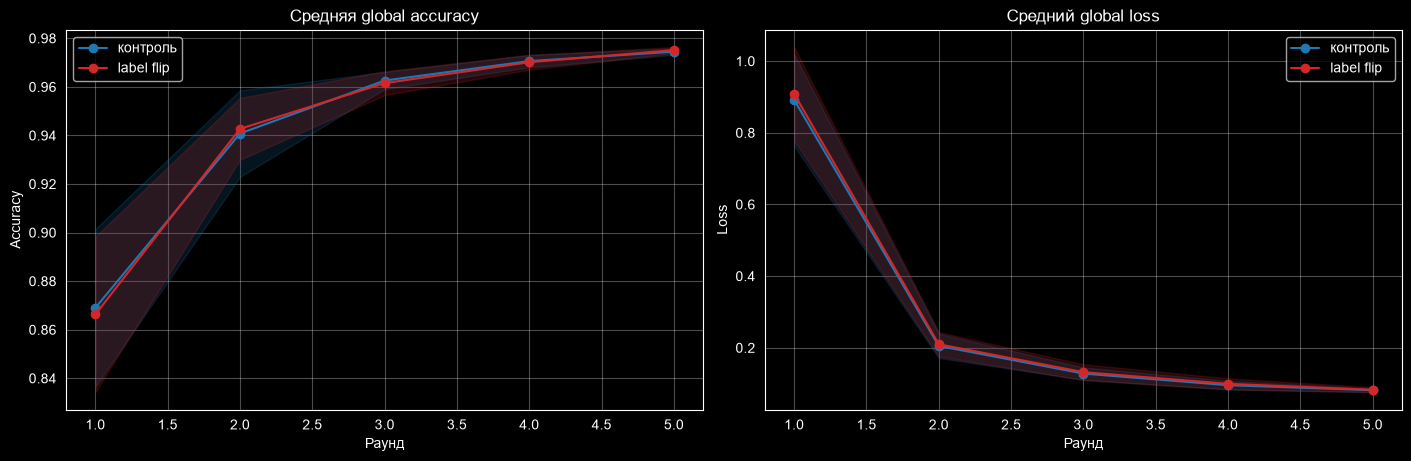

In [25]:
curve = round_metrics.groupby(['scenario', 'round'])[['global_accuracy', 'global_loss']].agg(['mean', 'std']).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
for scenario, label, color in [('control', 'контроль', 'tab:blue'), ('attack', 'label flip', 'tab:red')]:
    part = curve[curve['scenario'] == scenario]
    for axis, metric, title, ylabel in [(axes[0], 'global_accuracy', 'Средняя global accuracy', 'Accuracy'), (axes[1], 'global_loss', 'Средний global loss', 'Loss')]:
        mean = part[(metric, 'mean')].to_numpy()
        std = part[(metric, 'std')].fillna(0).to_numpy()
        rounds = part['round'].to_numpy()
        axis.plot(rounds, mean, marker='o', label=label, color=color)
        axis.fill_between(rounds, mean - std, mean + std, color=color, alpha=0.18)
        axis.set(title=title, xlabel='Раунд', ylabel=ylabel)
        axis.grid(alpha=0.3)
        axis.legend()
fig.savefig(REPORT_PICS_DIR / '04_single_label_flip_seed_series_global_learning_curves.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Поклассовые метрики и артефакты отчёта

,scenario,class_id,accuracy_mean,accuracy_std,loss_mean,loss_std
0,attack,1,0.990308,0.001526,0.047540,0.012512
1,attack,7,0.965629,0.011687,0.105527,0.027411
2,control,1,0.993245,0.002217,0.027059,0.005398
3,control,7,0.965629,0.010934,0.101849,0.027873


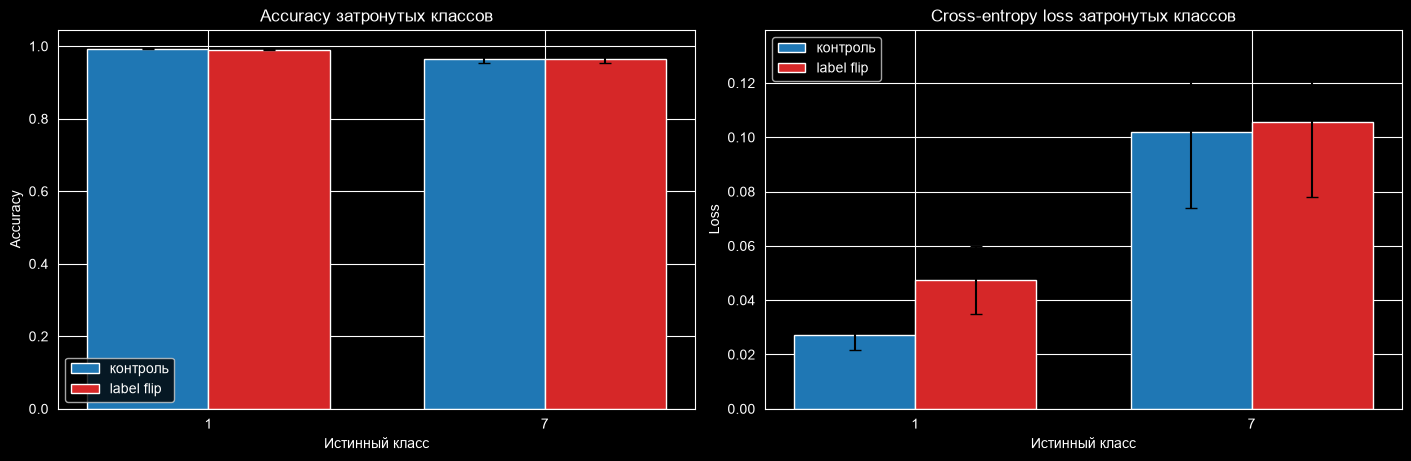

,seed,class_id,accuracy_delta,loss_delta
0,42,1,-0.006167,0.021041
1,42,7,0.001946,0.002348
2,43,1,-0.000881,0.012107
3,43,7,-0.001946,0.003552
4,44,1,-0.001762,0.028296
5,44,7,0.000000,0.005135


In [26]:
focus_classes = [base_config.attack.source_label, base_config.attack.target_label]
focus = class_metrics[class_metrics['class_id'].isin(focus_classes)].copy()
class_summary = focus.groupby(['scenario', 'class_id'])[['accuracy', 'loss']].agg(['mean', 'std']).reset_index()
class_summary_export = flatten_summary_columns(class_summary)
class_metrics.to_csv(SERIES_ARTIFACT_DIR / 'per_class_metrics_per_seed.csv', index=False)
class_summary_export.to_csv(SERIES_ARTIFACT_DIR / 'per_class_metrics_summary.csv', index=False)
display(class_summary_export)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
width = 0.36
x = np.arange(len(focus_classes))
for axis, metric, title, ylabel in [(axes[0], 'accuracy', 'Accuracy затронутых классов', 'Accuracy'), (axes[1], 'loss', 'Cross-entropy loss затронутых классов', 'Loss')]:
    for offset, scenario, label, color in [(-width / 2, 'control', 'контроль', 'tab:blue'), (width / 2, 'attack', 'label flip', 'tab:red')]:
        part = class_summary[class_summary['scenario'] == scenario].set_index('class_id').reindex(focus_classes)
        axis.bar(x + offset, part[(metric, 'mean')], width, yerr=part[(metric, 'std')].fillna(0), capsize=4, label=label, color=color)
    axis.set(title=title, xlabel='Истинный класс', ylabel=ylabel, xticks=x, xticklabels=focus_classes)
    axis.legend()
fig.savefig(REPORT_PICS_DIR / '04_single_label_flip_seed_series_per_class_effect.png', dpi=200, bbox_inches='tight')
plt.show()

class_paired = focus.pivot(index=['seed', 'class_id'], columns='scenario', values=['accuracy', 'loss'])
class_deltas = pd.DataFrame({'accuracy_delta': class_paired[('accuracy', 'attack')] - class_paired[('accuracy', 'control')], 'loss_delta': class_paired[('loss', 'attack')] - class_paired[('loss', 'control')]}).reset_index()
class_deltas.to_csv(SERIES_ARTIFACT_DIR / 'per_class_paired_deltas.csv', index=False)
display(class_deltas)

## 5. Реальный объём отравления по seed

При Non-IID-разбиении фиксированные доли вредоносных клиентов и заменяемых меток не означают одинаковое число реально изменённых образцов. Этот график нужен для корректной интерпретации основной серии.

Рисунок сохранён: C:\Users\neko\Desktop\projects\fed-learning-stand\practice_report\pics\04_single_label_flip_seed_series_poisoned_examples_by_seed.png


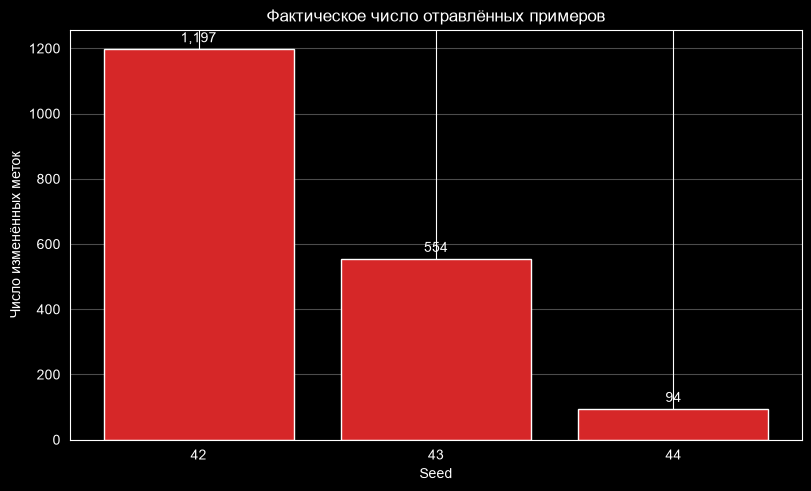

In [27]:
poison_by_seed = (global_metrics[global_metrics['scenario'] == 'attack'][['seed', 'poisoned_examples']]
                  .sort_values('seed')
                  .reset_index(drop=True))

fig, axis = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
bars = axis.bar(poison_by_seed['seed'].astype(str), poison_by_seed['poisoned_examples'], color='tab:red')
axis.bar_label(bars, labels=[f'{value:,}' for value in poison_by_seed['poisoned_examples']], padding=3)
axis.set(
    title='Фактическое число отравлённых примеров',
    xlabel='Seed',
    ylabel='Число изменённых меток',
)
axis.grid(axis='y', alpha=0.3)

figure_path = REPORT_PICS_DIR / '04_single_label_flip_seed_series_poisoned_examples_by_seed.png'
fig.savefig(figure_path, dpi=200, bbox_inches='tight')
print(f'Рисунок сохранён: {figure_path}')
plt.show()

## 6. Краткая сводка для отчёта

In [28]:
summary_for_report = {
    'seeds': list(SEEDS),
    'attack': {'type': base_config.attack.type, 'source_label': base_config.attack.source_label, 'target_label': base_config.attack.target_label, 'malicious_fraction': base_config.attack.malicious_fraction, 'poison_fraction': base_config.attack.poison_fraction},
    'global_delta_mean': deltas[['accuracy_delta', 'loss_delta', 'macro_f1_delta']].mean().to_dict(),
    'global_delta_std': deltas[['accuracy_delta', 'loss_delta', 'macro_f1_delta']].std(ddof=1).to_dict(),
}
(SERIES_ARTIFACT_DIR / 'series_summary.json').write_text(json.dumps(summary_for_report, indent=2), encoding='utf-8')
report_markdown = f'''
### Результат серии

Выполнено парных сравнений: **{len(SEEDS)}**. CSV и JSON для отчёта сохранены в `{SERIES_ARTIFACT_DIR}`.

Среднее изменение «атака − контроль»: accuracy **{summary_for_report['global_delta_mean']['accuracy_delta']:+.4f} ± {summary_for_report['global_delta_std']['accuracy_delta']:.4f}**, loss **{summary_for_report['global_delta_mean']['loss_delta']:+.4f} ± {summary_for_report['global_delta_std']['loss_delta']:.4f}**.

Интерпретируйте результат вместе с поклассовыми метриками: global accuracy может скрывать эффект на классе-источнике атаки.
'''
(SERIES_ARTIFACT_DIR / 'series_summary.md').write_text(report_markdown, encoding='utf-8')
display(Markdown(report_markdown))


### Результат серии

Выполнено парных сравнений: **3**. CSV и JSON для отчёта сохранены в `C:\Users\neko\Desktop\projects\fed-learning-stand\notebooks\results\single-label-flip-seed-series`.

Среднее изменение «атака − контроль»: accuracy **+0.0006 ± 0.0002**, loss **+0.0012 ± 0.0020**.

Интерпретируйте результат вместе с поклассовыми метриками: global accuracy может скрывать эффект на классе-источнике атаки.
